In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

flood_df = pd.read_csv('/content/drive/MyDrive/DS PROJ101/bkk_flood_50_districts.csv')
budget_df = pd.read_csv('/content/drive/MyDrive/DS PROJ101/bkk_budget_by_project.csv')

print("--- Flood DataFrame ---")
print(flood_df.head())
print("\n--- Budget DataFrame ---")
print(budget_df.head())

--- Flood DataFrame ---
    district budget_drainge_dept (THB) budget_district_office (THB)  \
0    คลองเตย               176,175,340                    3,422,100   
1    คลองสาน                71,922,000                    5,648,910   
2  คลองสามวา                18,380,200                    4,180,900   
3   คันนายาว                         0                    3,025,600   
4    จตุจักร               112,204,207                   26,846,600   

  total_budget (THB)  total_budget (MB)  flood_count  total_rainfall (mm)  \
0        179,597,440             179.60           17               1219.0   
1         77,570,910              77.57            5                352.5   
2         22,561,100              22.56            0                  NaN   
3          3,025,600               3.03            2                158.5   
4        139,050,807             139.05           33               2598.5   

   avg_rainfall (mm)  total_drain_time (min)  avg_drain_time (min)  \
0               

In [ ]:
print("=== Flood DataFrame Info ===")
print(f"Shape: {flood_df.shape}")
print(f"Columns: {list(flood_df.columns)}")
print(flood_df.info())

print("\n=== Budget DataFrame Info ===")
print(f"Shape: {budget_df.shape}")
print(f"Columns: {list(budget_df.columns)}")
print(budget_df.info())

=== Flood DataFrame Info ===
Shape: (50, 13)
Columns: ['district', 'budget_drainge_dept (THB)', 'budget_district_office (THB)', 'total_budget (THB)', 'total_budget (MB)', 'flood_count', 'total_rainfall (mm)', 'avg_rainfall (mm)', 'total_drain_time (min)', 'avg_drain_time (min)', 'budget_per_flood (MB)', 'bkk_zone', 'flood_record_status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   district                      50 non-null     object 
 1   budget_drainge_dept (THB)     50 non-null     object 
 2   budget_district_office (THB)  50 non-null     object 
 3   total_budget (THB)            50 non-null     object 
 4   total_budget (MB)             50 non-null     float64
 5   flood_count                   50 non-null     int64  
 6   total_rainfall (mm)           39 non-null     float64
 7   avg_rainfall (mm)    

In [ ]:
thai_to_eng_districts = {
    'คลองสาน': 'Khlong San',
    'คลองสามวา': 'Khlong Sam Wa',
    'คลองเตย': 'Khlong Toei',
    'คันนายาว': 'Khan Na Yao',
    'จตุจักร': 'Chatuchak',
    'จอมทอง': 'Chom Thong',
    'ดอนเมือง': 'Don Mueang',
    'ดินแดง': 'Din Daeng',
    'ดุสิต': 'Dusit',
    'ตลิ่งชัน': 'Taling Chan',
    'ทวีวัฒนา': 'Thawi Watthana',
    'ทุ่งครุ': 'Thung Khru',
    'ธนบุรี': 'Thon Buri',
    'บางกะปิ': 'Bang Kapi',
    'บางกอกน้อย': 'Bangkok Noi',
    'บางกอกใหญ่': 'Bangkok Yai',
    'บางขุนเทียน': 'Bang Khun Thian',
    'บางคอแหลม': 'Bang Kho Laem',
    'บางซื่อ': 'Bang Sue',
    'บางนา': 'Bang Na',
    'บางบอน': 'Bang Bon',
    'บางพลัด': 'Bang Phlat',
    'บางรัก': 'Bang Rak',
    'บางเขน': 'Bang Khen',
    'บางแค': 'Bang Khae',
    'บึงกุ่ม': 'Bueng Kum',
    'ปทุมวัน': 'Pathum Wan',
    'ประเวศ': 'Prawet',
    'ป้อมปราบศัตรูพ่าย': 'Pom Prap Sattru Phai',
    'พญาไท': 'Phaya Thai',
    'พระนคร': 'Phra Nakhon',
    'พระโขนง': 'Phra Khanong',
    'ภาษีเจริญ': 'Phasi Charoen',
    'มีนบุรี': 'Min Buri',
    'ยานนาวา': 'Yan Nawa',
    'ราชเทวี': 'Ratchathewi',
    'ราษฎร์บูรณะ': 'Rat Burana',
    'ลาดกระบัง': 'Lat Krabang',
    'ลาดพร้าว': 'Lat Phrao',
    'วังทองหลาง': 'Wang Thonglang',
    'วัฒนา': 'Watthana',
    'สวนหลวง': 'Suan Luang',
    'สะพานสูง': 'Saphan Sung',
    'สัมพันธวงศ์': 'Samphanthawong',
    'สาทร': 'Sathon',
    'สายไหม': 'Sai Mai',
    'หนองจอก': 'Nong Chok',
    'หนองแขม': 'Nong Khaem',
    'หลักสี่': 'Lak Si',
    'ห้วยขวาง': 'Huai Khwang'
}

thai_to_eng_zones = {
    'กรุงเทพเหนือ': 'North BKK',
    'กรุงเทพใต้': 'South BKK',
    'กรุงเทพกลาง': 'Central BKK',
    'กรุงเทพตะวันออก': 'East BKK',
    'กรุงธนเหนือ': 'North Thonburi',
    'กรุงธนใต้': 'South Thonburi'
}

flood_df['district_en'] = flood_df['district'].map(thai_to_eng_districts).fillna(flood_df['district'])
flood_df['zone_en'] = flood_df['bkk_zone'].map(thai_to_eng_zones).fillna(flood_df['bkk_zone'])



/tmp/ipykernel_1168/2958720858.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_flood, x='flood_count', y='district_en', palette='Reds_r')


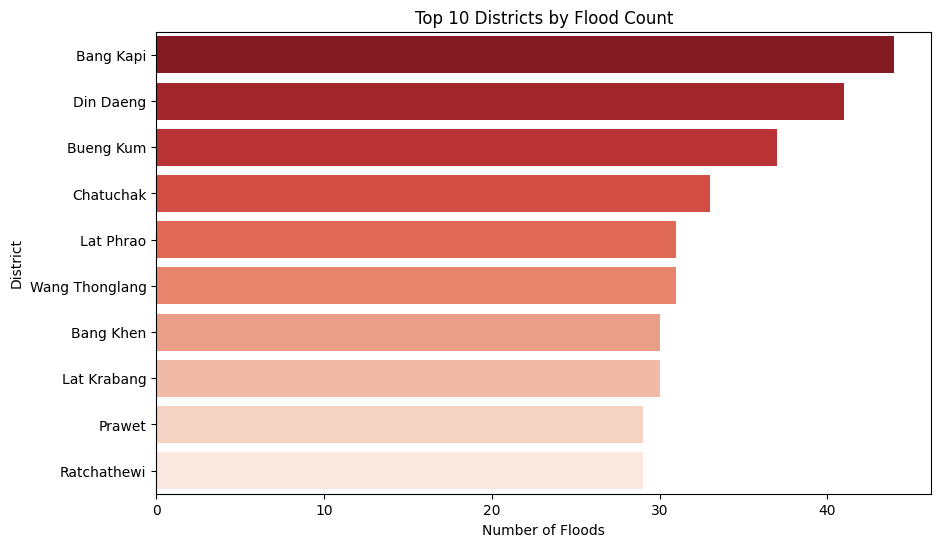

In [ ]:
plt.figure(figsize=(10, 6))
top_flood = flood_df.nlargest(10, 'flood_count')

sns.barplot(data=top_flood, x='flood_count', y='district_en', palette='Reds_r')
plt.title('Top 10 Districts by Flood Count')
plt.xlabel('Number of Floods')
plt.ylabel('District')
plt.show()

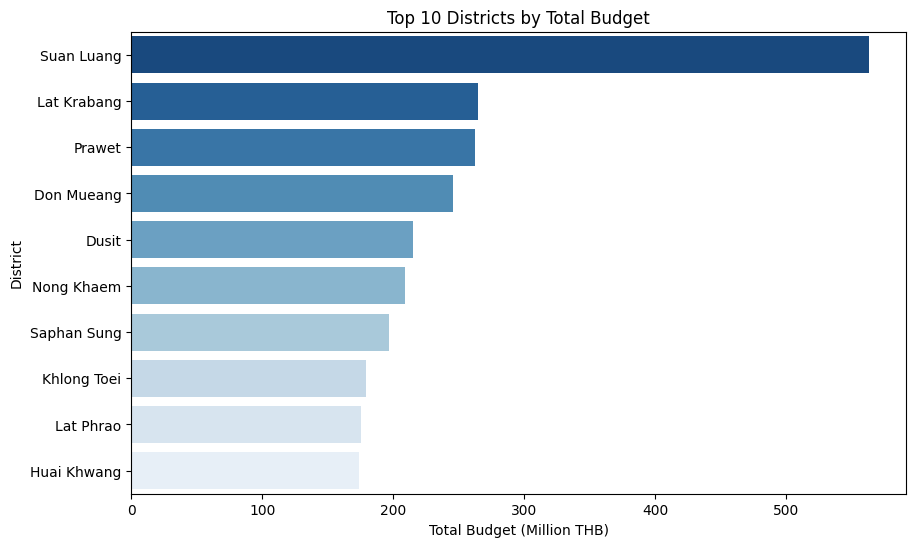

In [ ]:
plt.figure(figsize=(10, 6))

top_budget = flood_df.nlargest(10, 'total_budget (MB)')

sns.barplot(data=top_budget, x='total_budget (MB)', y='district_en', hue='district_en', palette='Blues_r', legend=False)
plt.title('Top 10 Districts by Total Budget')
plt.xlabel('Total Budget (Million THB)')
plt.ylabel('District')
plt.show()

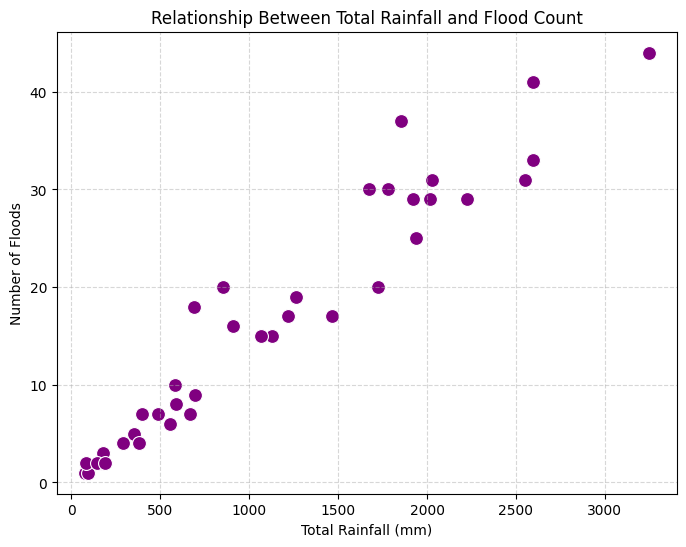

In [ ]:
plt.figure(figsize=(8, 6))

df_rain = flood_df.dropna(subset=['total_rainfall (mm)', 'flood_count'])

sns.scatterplot(data=df_rain, x='total_rainfall (mm)', y='flood_count', color='purple', s=100)
plt.title('Relationship Between Total Rainfall and Flood Count')
plt.xlabel('Total Rainfall (mm)')
plt.ylabel('Number of Floods')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

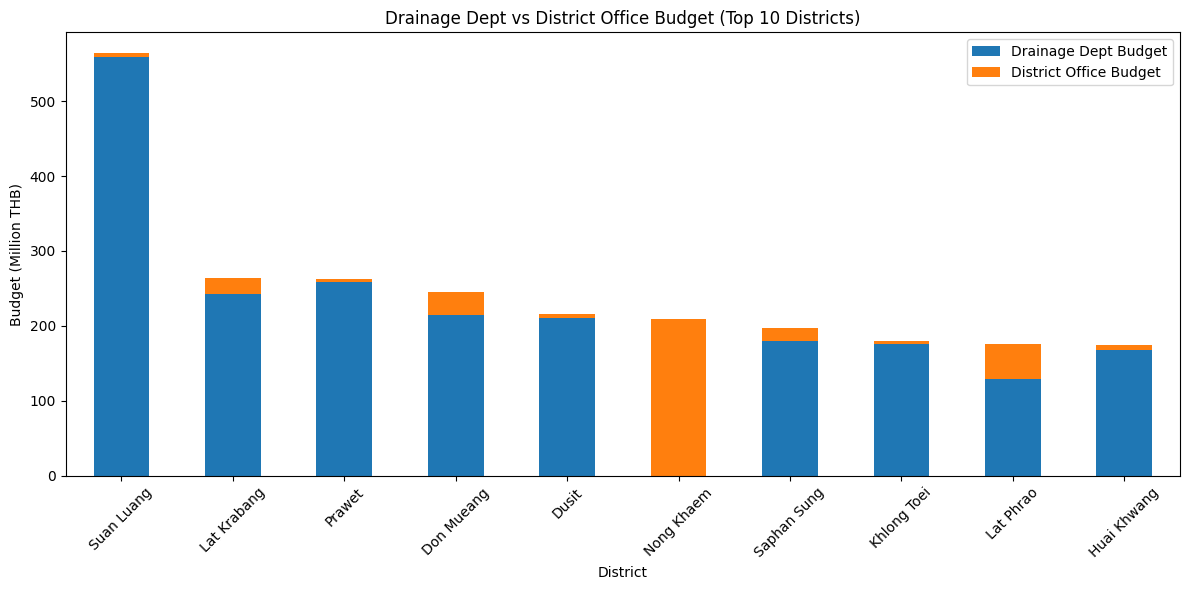

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plot_df = flood_df.copy()
plot_df['budget_drainge_dept_val'] = plot_df['budget_drainge_dept (THB)'].astype(str).str.replace(',', '').astype(float)
plot_df['budget_district_office_val'] = plot_df['budget_district_office (THB)'].astype(str).str.replace(',', '').astype(float)
plot_df['total_budget_val'] = plot_df['budget_drainge_dept_val'] + plot_df['budget_district_office_val']

top10_budget_districts = plot_df.nlargest(10, 'total_budget_val')

top10_budget_districts['Drainage Dept (Million THB)'] = top10_budget_districts['budget_drainge_dept_val'] / 1e6
top10_budget_districts['District Office (Million THB)'] = top10_budget_districts['budget_district_office_val'] / 1e6

top10_budget_districts.set_index('district_en')[['Drainage Dept (Million THB)', 'District Office (Million THB)']].plot(
    kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], figsize=(12, 6)
)

plt.title('Drainage Dept vs District Office Budget (Top 10 Districts)')
plt.xlabel('District')
plt.ylabel('Budget (Million THB)')
plt.xticks(rotation=45)
plt.legend(['Drainage Dept Budget', 'District Office Budget'])
plt.tight_layout()
plt.show()

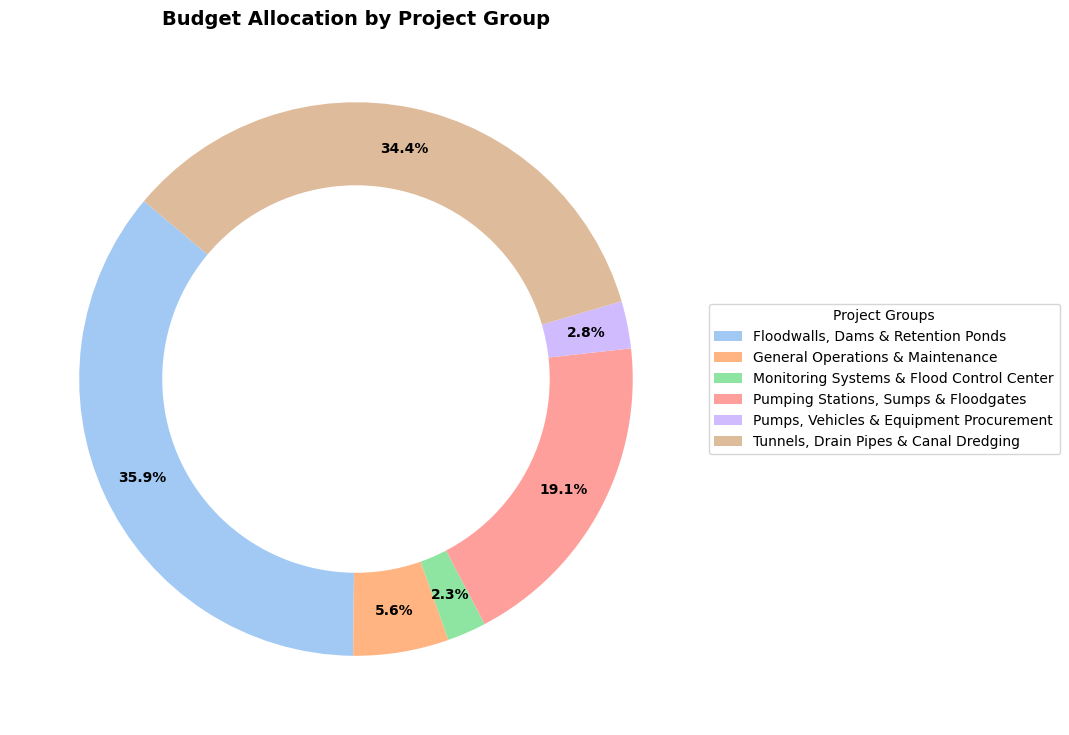

In [ ]:
plt.figure(figsize=(10, 8))

project_group_map = {
    'เขื่อนและแนวป้องกันน้ำท่วม/แก้มลิง': 'Floodwalls, Dams & Retention Ponds',
    'อุโมงค์ ท่อระบายน้ำ และขุดลอกคลอง': 'Tunnels, Drain Pipes & Canal Dredging',
    'งบดำเนินงานและบำรุงรักษาทั่วไป': 'General Operations & Maintenance',
    'สถานีสูบน้ำ บ่อสูบน้ำ และประตูระบายน้ำ': 'Pumping Stations, Sumps & Floodgates',
    'จัดซื้อเครื่องสูบน้ำ ยานพาหนะ และอุปกรณ์': 'Pumps, Vehicles & Equipment Procurement',
    'ระบบตรวจวัดและศูนย์ควบคุมน้ำท่วม': 'Monitoring Systems & Flood Control Center'
}

budget_df['project_group_en'] = budget_df['project_group'].map(project_group_map).fillna(budget_df['project_group'])

project_group_sum = budget_df.groupby('project_group_en')['budget_mb'].sum().reset_index()

wedges, texts, autotexts = plt.pie(
    project_group_sum['budget_mb'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel'),
    pctdistance=0.85,
    textprops=dict(color="black", weight="bold")
)

centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.legend(
    wedges,
    project_group_sum['project_group_en'],
    title="Project Groups",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

plt.title('Budget Allocation by Project Group', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1168/1313762499.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=flood_df, x='zone_en', y='total_budget (MB)', palette='Set2')


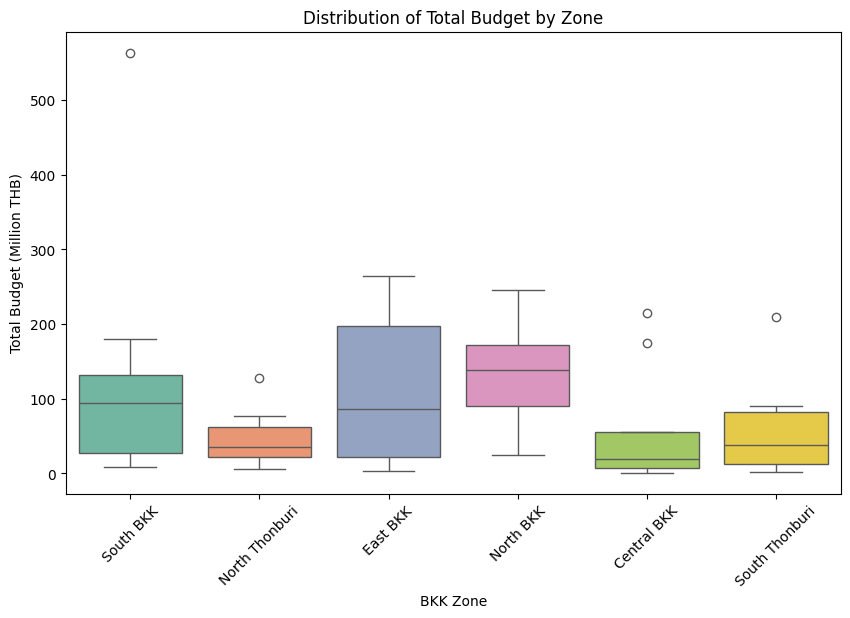

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=flood_df, x='zone_en', y='total_budget (MB)', palette='Set2')

plt.title('Distribution of Total Budget by Zone')
plt.xlabel('BKK Zone')
plt.ylabel('Total Budget (Million THB)')
plt.xticks(rotation=45)
plt.show()

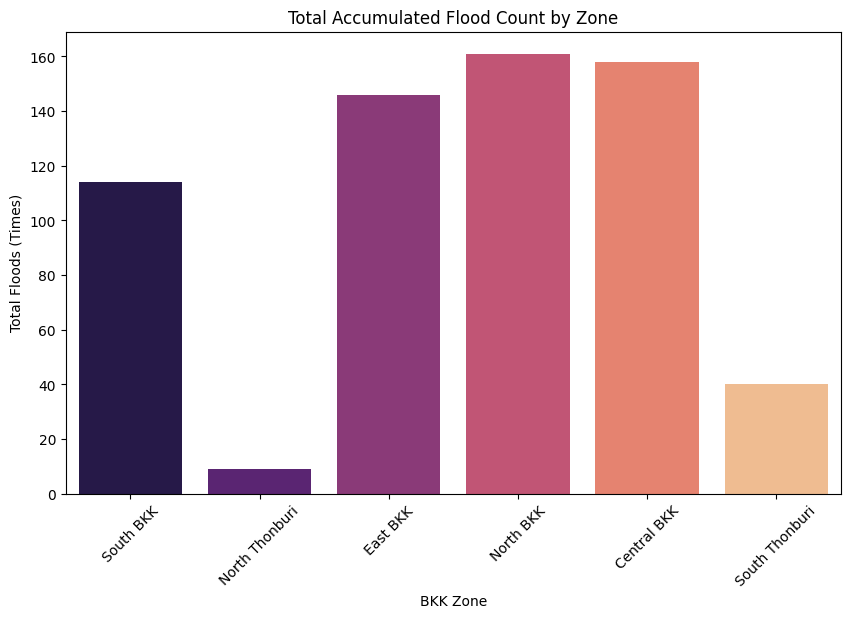

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(data=flood_df, x='zone_en', y='flood_count', estimator=sum, errorbar=None, hue='zone_en', palette='magma', legend=False)

plt.title('Total Accumulated Flood Count by Zone')
plt.xlabel('BKK Zone')
plt.ylabel('Total Floods (Times)')
plt.xticks(rotation=45)
plt.show()

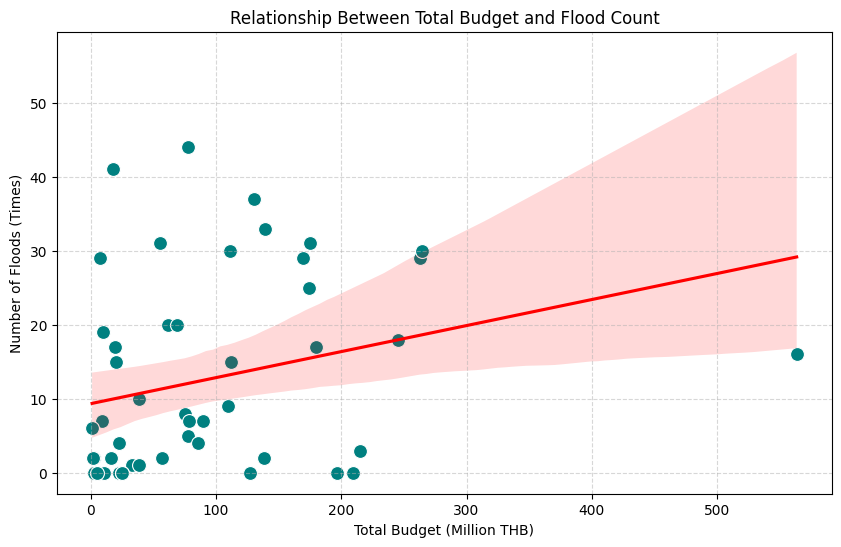

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=flood_df, x='total_budget (MB)', y='flood_count', s=100, color='teal')
sns.regplot(data=flood_df, x='total_budget (MB)', y='flood_count', scatter=False, color='red')
plt.title('Relationship Between Total Budget and Flood Count')
plt.xlabel('Total Budget (Million THB)')
plt.ylabel('Number of Floods (Times)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

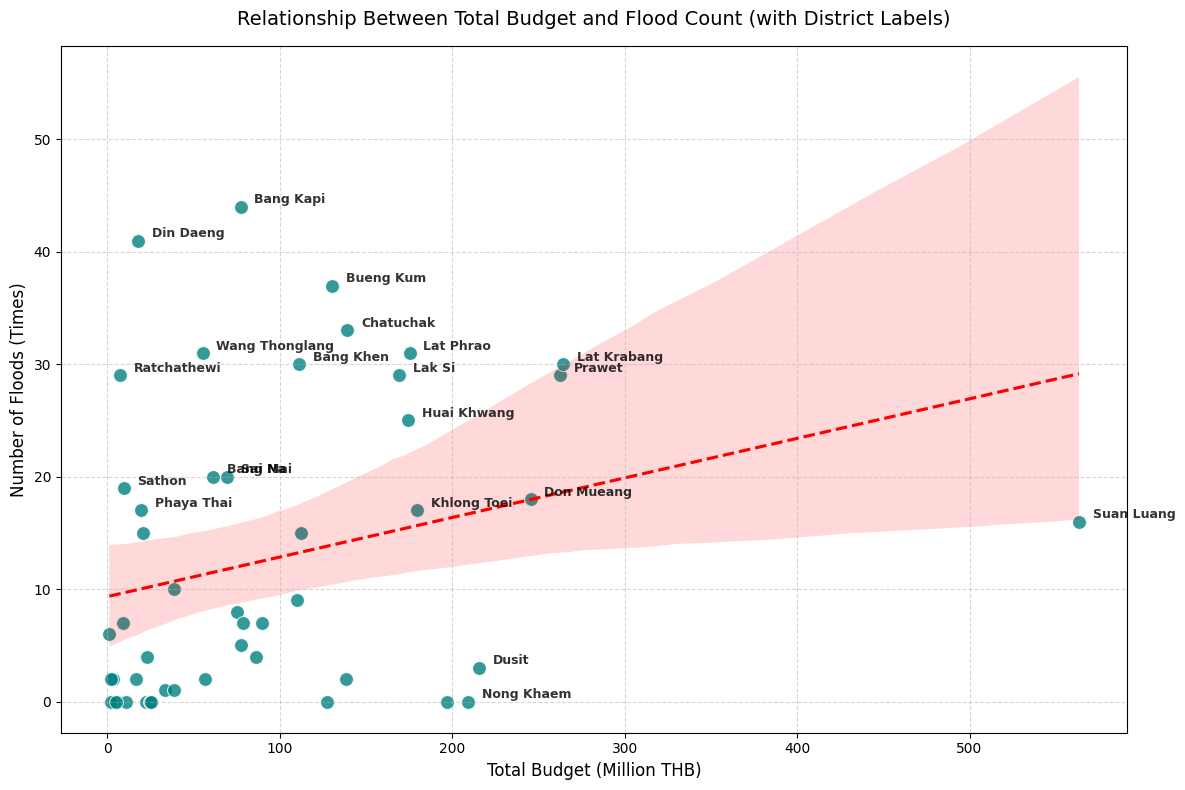

In [ ]:
plt.figure(figsize=(12, 8))

sns.scatterplot(data=flood_df, x='total_budget (MB)', y='flood_count', s=100, color='teal', alpha=0.8)
sns.regplot(data=flood_df, x='total_budget (MB)', y='flood_count', scatter=False, color='red', line_kws={'linestyle': '--'})

for idx, row in flood_df.iterrows():
    if row['total_budget (MB)'] > 200 or row['flood_count'] > 15:
        plt.text(
            row['total_budget (MB)'] + 8,
            row['flood_count'] + 0.3,
            row['district_en'],
            fontsize=9,
            weight='semibold',
            alpha=0.8
        )

plt.title('Relationship Between Total Budget and Flood Count (with District Labels)', fontsize=14, pad=15)
plt.xlabel('Total Budget (Million THB)', fontsize=12)
plt.ylabel('Number of Floods (Times)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()